In [3]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Load and validate optimised parameters


In [8]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """Fixed point equation for green neurons"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)
    return g_new

# Solve fixed point via Anderson Acceleration
def solve_fixed_point(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)
    return r, g, b, y

In [7]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [9]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


# Compute Hessian 

For each valid parameter set, we compute the Hessian matrix of the output function and extract its eigenvalues and eigenvectors. The eigenvectors corresponding to near-zero eigenvalues represent directions in parameter space where changes preserve the output.

Processing 982 samples...
  Sample 1/982...
  Sample 101/982...
  Sample 201/982...
  Sample 301/982...
  Sample 401/982...
  Sample 501/982...
  Sample 601/982...
  Sample 701/982...
  Sample 801/982...
  Sample 901/982...
Completed processing 982 samples


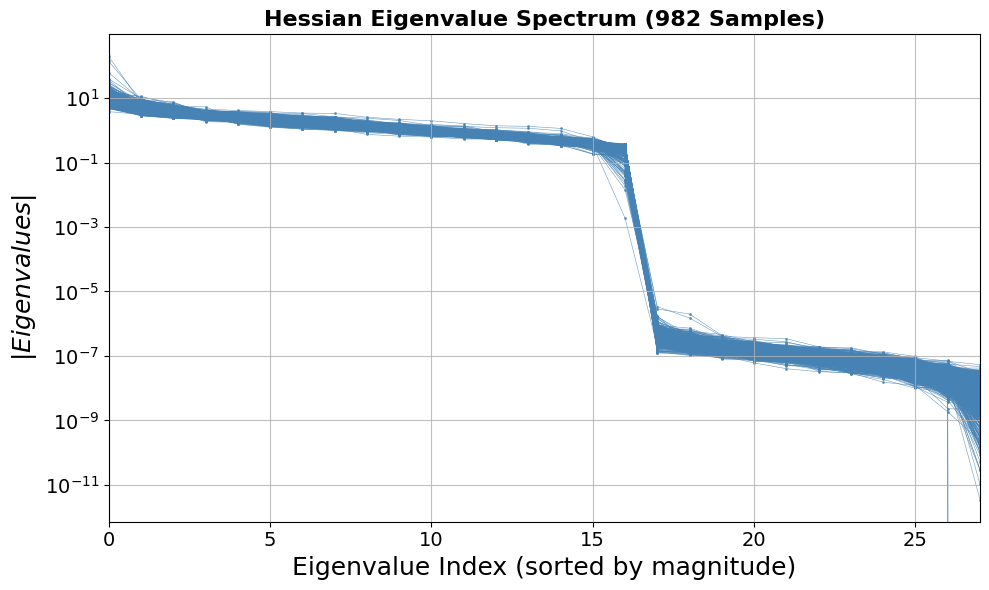

In [10]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [11]:
all_eigenvectors.shape
all_eigenvalues.shape

(982, 28)

- For each sample, there are 2 subspaces: eigenvalue > 0.00001 and eigenvalues < 0.00001
- For eigenvalues < 0.00001, each value corresponds to an eigenvector, which represents a space
- Do pairwise comparisons with samples of second subspace to see if they represent the same space
- Do this by concatenating the eigenvectors of sample 1 subspace 2, and sample 2 subspace 2, and then take the rank
- Use SVD
- Start with simple example first, later expand to all pairwise comparisons


In [12]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)
    
    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)
    
    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)
    
    return eigenvectors_subspace2

In [13]:

def compare_subspaces(sample1_idx, sample2_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5, tol=0.1):
    
    ev1 = get_subspace2_eigenvectors(sample1_idx, all_eigenvalues, all_eigenvectors, threshold)
    ev2 = get_subspace2_eigenvectors(sample2_idx, all_eigenvalues, all_eigenvectors, threshold)
    
    n_vectors_1 = ev1.shape[0]
    n_vectors_2 = ev2.shape[0]

    concatenated = np.vstack([ev1, ev2])  # Shape: (n_vectors_1 + n_vectors_2, n_params)
    
    U, s, Vt = np.linalg.svd(concatenated)

    tol = tol 
    rank = np.sum(s > tol)

    return s, rank, n_vectors_1, n_vectors_2



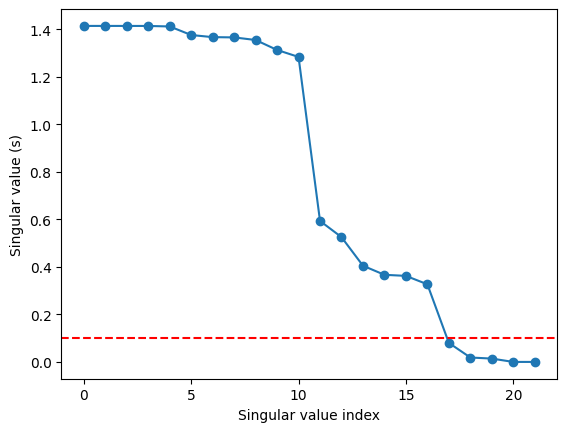

In [29]:

sample1_idx = 0
sample2_idx = 10

tol = 0.1
s, rank, n1, n2 = compare_subspaces(sample1_idx, sample2_idx, 
                                           all_eigenvalues, all_eigenvectors, 
                                           threshold=threshold, tol=tol)

plt.plot(s, "-o")
plt.axhline(y=tol, color='r', linestyle='--')
plt.xlabel("Singular value index")
plt.ylabel("Singular value (s)")
plt.show()

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


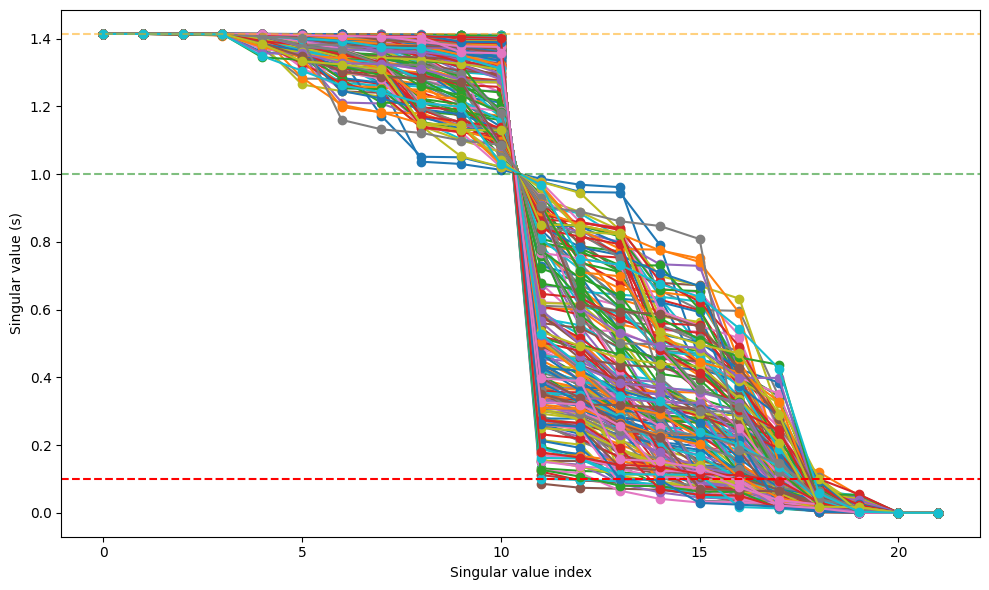

In [27]:
# Test all pairwise comparisons of samples and plot the singular values (s) for each one on the same plot

num_samples = 20 #len(all_eigenvalues)
tol = 0.1

plt.figure(figsize=(10, 6))
for i in range(num_samples):
    print(i)
    for j in range(i+1, num_samples):
        s, rank, n1, n2 = compare_subspaces(i, j, all_eigenvalues, all_eigenvectors, threshold=threshold, tol=tol)
        plt.plot(s, "-o", label=f"Samples {i} & {j}")

plt.axhline(y=tol, color='r', linestyle='--', label='Tolerance')
plt.axhline(y=1.0, color='g', linestyle='--', alpha=0.5, label='Orthogonal')
plt.axhline(y=np.sqrt(2), color='orange', linestyle='--', alpha=0.5, label='Identical vectors')
plt.xlabel("Singular value index")
plt.ylabel("Singular value (s)")

plt.tight_layout()
plt.show()

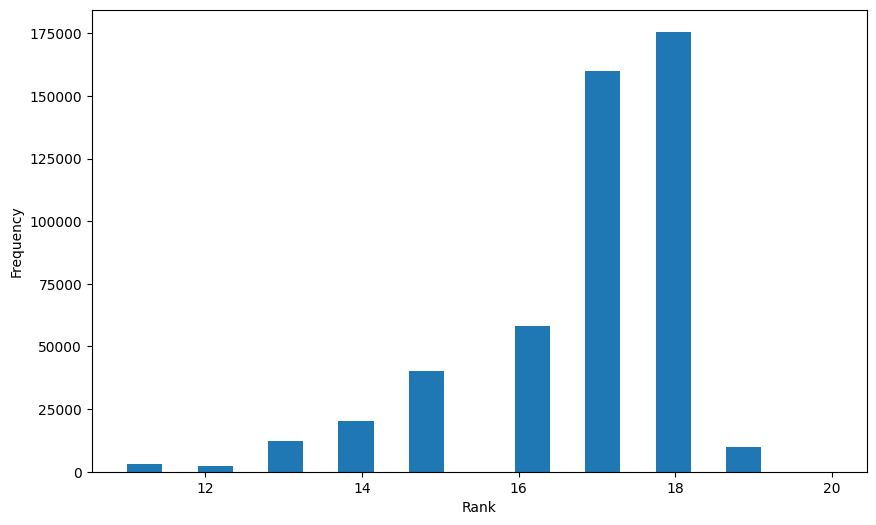

In [23]:
# Test all pairwise comparisons of samples and plot the singular values (s) for each one on the same plot

num_samples = len(all_eigenvalues)
tol = 0.1

plt.figure(figsize=(10, 6))
rank_list = []
for i in range(num_samples):
    for j in range(i+1, num_samples):
        s, rank, n1, n2 = compare_subspaces(i, j, all_eigenvalues, all_eigenvectors, threshold=threshold, tol=tol)
        rank_list.append(rank)

#plot histogram of rank_list
plt.hist(rank_list, bins=20)
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.show()
